In [2]:
TARGET_RECALL = 0.90

print("Target Recall:", TARGET_RECALL)

Target Recall: 0.9


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    OrdinalEncoder
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC


print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
x_train = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/x_train.csv")
x_test = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/x_test.csv")

y_train = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("C:/Projects/smart-industrial-predictive-maintenance/data/processed/y_test.csv").squeeze()


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference"
]

class_weight_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

smote_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ],
    sparse_threshold=0
)

rf_class_weight = Pipeline(steps=[
    ("preprocessor", class_weight_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

rf_smotenc = ImbPipeline(steps=[
    ("preprocessor", smote_preprocessor),
    ("smotenc", SMOTENC(
        categorical_features=[0],
        random_state=42,
        k_neighbors=5
    )),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [6]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

class_weight_oof = cross_val_predict(
    rf_class_weight,
    x_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

smotenc_oof = cross_val_predict(
    rf_smotenc,
    x_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [7]:
def find_recall_threshold(
    y_true,
    probabilities,
    target_recall=0.90
):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # Align precision and recall with thresholds
    precision = precision[:-1]
    recall = recall[:-1]

    # Find thresholds achieving the target recall
    valid_indices = np.where(
        recall >= target_recall
    )[0]

    if len(valid_indices) == 0:

        print("Target Recall cannot be achieved.")

        best_index = np.argmax(recall)

    else:

        # Choose the highest threshold
        # that still achieves target Recall
        best_index = valid_indices[
            np.argmax(thresholds[valid_indices])
        ]

    selected_threshold = thresholds[best_index]

    selected_precision = precision[best_index]
    selected_recall = recall[best_index]

    selected_f1 = (
        2 * selected_precision * selected_recall /
        (selected_precision + selected_recall + 1e-10)
    )

    return {
        "Threshold": selected_threshold,
        "Precision": selected_precision,
        "Recall": selected_recall,
        "F1 Score": selected_f1,
        "Target Achieved": selected_recall >= target_recall
    }

In [8]:
class_weight_threshold = find_recall_threshold(
    y_train,
    class_weight_oof,
    TARGET_RECALL
)

smotenc_threshold = find_recall_threshold(
    y_train,
    smotenc_oof,
    TARGET_RECALL
)

print("CLASS WEIGHT RESULTS")
print(class_weight_threshold)

print("\nSMOTENC RESULTS")
print(smotenc_threshold)

CLASS WEIGHT RESULTS
{'Threshold': np.float64(0.13), 'Precision': np.float64(0.34807417974322397), 'Recall': np.float64(0.9003690036900369), 'F1 Score': np.float64(0.5020576131285096), 'Target Achieved': np.True_}

SMOTENC RESULTS
{'Threshold': np.float64(0.22), 'Precision': np.float64(0.3398328690807799), 'Recall': np.float64(0.9003690036900369), 'F1 Score': np.float64(0.4934277047124889), 'Target Achieved': np.True_}


In [9]:
threshold_results = pd.DataFrame([
    {
        "Model": "Random Forest - Class Weight",
        **class_weight_threshold
    },
    {
        "Model": "Random Forest - SMOTENC",
        **smotenc_threshold
    }
])

threshold_results

,Model,Threshold,Precision,Recall,F1 Score,Target Achieved
0,Random Forest - Class Weight,0.13,0.348074,0.900369,0.502058,True
1,Random Forest - SMOTENC,0.22,0.339833,0.900369,0.493428,True


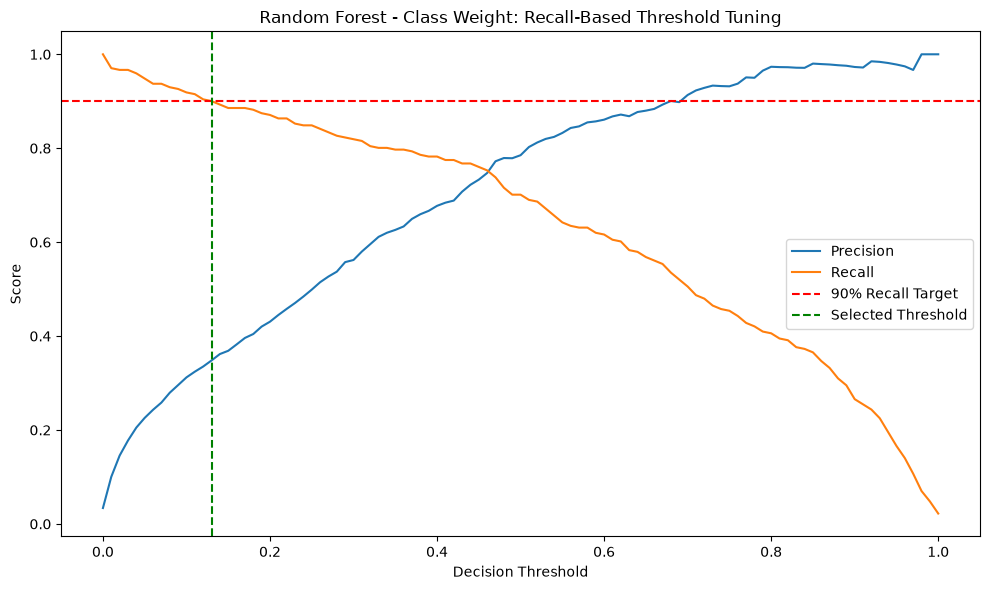

In [10]:
precision, recall, thresholds = precision_recall_curve(
    y_train,
    class_weight_oof
)

plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    precision[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall[:-1],
    label="Recall"
)

plt.axhline(
    TARGET_RECALL,
    color="red",
    linestyle="--",
    label="90% Recall Target"
)

plt.axvline(
    class_weight_threshold["Threshold"],
    color="green",
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Random Forest - Class Weight: Recall-Based Threshold Tuning"
)

plt.legend()
plt.tight_layout()
plt.show()

In [11]:
print("Training Class Weight Random Forest...")

rf_class_weight.fit(
    x_train,
    y_train
)


print("Training SMOTENC Random Forest...")

rf_smotenc.fit(
    x_train,
    y_train
)


print("Both models trained successfully!")

Training Class Weight Random Forest...
Training SMOTENC Random Forest...
Both models trained successfully!


In [12]:
class_weight_probabilities = (
    rf_class_weight.predict_proba(x_test)[:, 1]
)

smotenc_probabilities = (
    rf_smotenc.predict_proba(x_test)[:, 1]
)

print("Failure probabilities generated!")

Failure probabilities generated!


In [13]:
class_weight_predictions = (
    class_weight_probabilities >=
    class_weight_threshold["Threshold"]
).astype(int)


smotenc_predictions = (
    smotenc_probabilities >=
    smotenc_threshold["Threshold"]
).astype(int)


print("Recall-based predictions generated!")

Recall-based predictions generated!


In [14]:
def evaluate_model(
    y_true,
    predictions,
    probabilities,
    model_name
):

    return {
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_true, predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),

        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


final_results = pd.DataFrame([
    evaluate_model(
        y_test,
        class_weight_predictions,
        class_weight_probabilities,
        "Random Forest - Class Weight"
    ),

    evaluate_model(
        y_test,
        smotenc_predictions,
        smotenc_probabilities,
        "Random Forest - SMOTENC"
    )
])

final_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest - Class Weight,0.943,0.366279,0.926471,0.525,0.971072,0.844610
1,Random Forest - SMOTENC,0.938,0.344444,0.911765,0.500,0.974447,0.816873


In [15]:
print("CLASS WEIGHT RANDOM FOREST")

print(classification_report(
    y_test,
    class_weight_predictions,
    zero_division=0
))


print("\nSMOTENC RANDOM FOREST")

print(classification_report(
    y_test,
    smotenc_predictions,
    zero_division=0
))

CLASS WEIGHT RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      1932
           1       0.37      0.93      0.53        68

    accuracy                           0.94      2000
   macro avg       0.68      0.94      0.75      2000
weighted avg       0.98      0.94      0.95      2000


SMOTENC RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      1932
           1       0.34      0.91      0.50        68

    accuracy                           0.94      2000
   macro avg       0.67      0.93      0.73      2000
weighted avg       0.97      0.94      0.95      2000



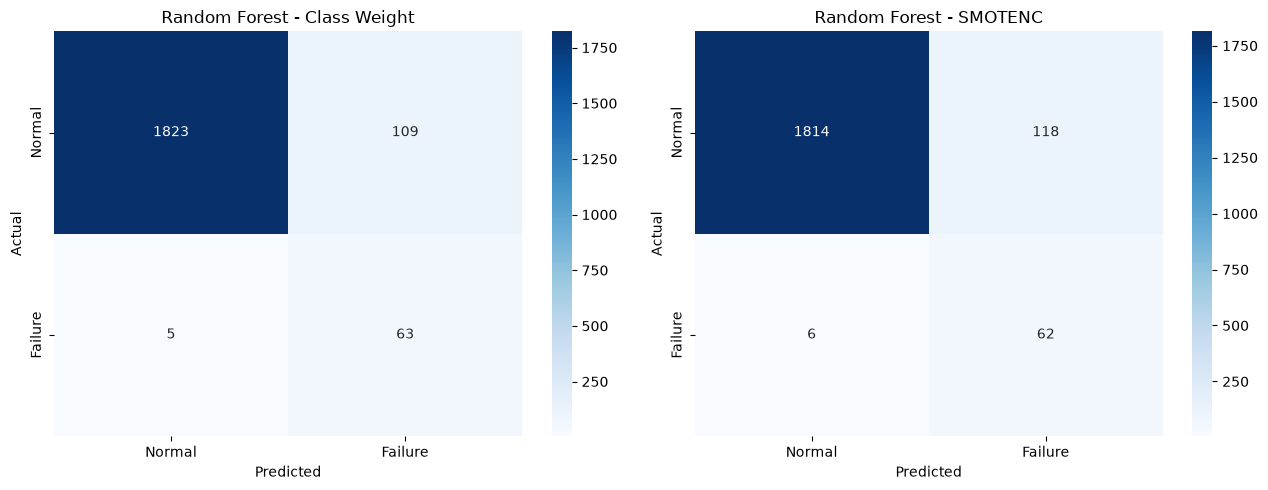

In [16]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

predictions_list = [
    ("Class Weight", class_weight_predictions),
    ("SMOTENC", smotenc_predictions)
]

for ax, (name, predictions) in zip(
    axes,
    predictions_list
):

    cm = confusion_matrix(
        y_test,
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Failure"],
        yticklabels=["Normal", "Failure"],
        ax=ax
    )

    ax.set_title(
        f"Random Forest - {name}"
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [17]:
for name, predictions in predictions_list:

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    print("\n", name)

    print("Correct normal predictions:", tn)
    print("False failure alarms:", fp)
    print("Missed machine failures:", fn)
    print("Correctly detected failures:", tp)

    print(
        "Recall:",
        round(tp / (tp + fn), 4)
    )


 Class Weight
Correct normal predictions: 1823
False failure alarms: 109
Missed machine failures: 5
Correctly detected failures: 63
Recall: 0.9265

 SMOTENC
Correct normal predictions: 1814
False failure alarms: 118
Missed machine failures: 6
Correctly detected failures: 62
Recall: 0.9118


In [18]:
import os

os.makedirs("../reports", exist_ok=True)

threshold_results.to_csv(
    "../reports/threshold_cv_results.csv",
    index=False
)

final_results.to_csv(
    "../reports/final_model_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [19]:
import joblib
from pathlib import Path


current_dir = Path.cwd()

if (current_dir / "models").exists():
    project_root = current_dir
elif (current_dir.parent / "models").exists():
    project_root = current_dir.parent
else:
    raise FileNotFoundError("models folder not found!")

models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)


best_threshold = 0.13


model_bundle = {
    "model": rf_class_weight,
    "threshold": best_threshold,
    "model_name": "Random Forest - Class Weight",
    "positive_class": 1
}

model_path = models_dir / "random_forest_class_weight.joblib"

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("Selected threshold:", best_threshold)

Model saved successfully!
Location: c:\Projects\smart-industrial-predictive-maintenance\models\random_forest_class_weight.joblib
Selected threshold: 0.13
